In [92]:
#I'm gonna import everything all at once here
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import warnings
from datetime import datetime
from prophet import Prophet

,date,Number of hours watched in millions
0,2018-01-01,89.0
1,2018-02-01,81.0
2,2018-03-01,88.8
3,2018-04-01,74.1
4,2018-05-01,82.0


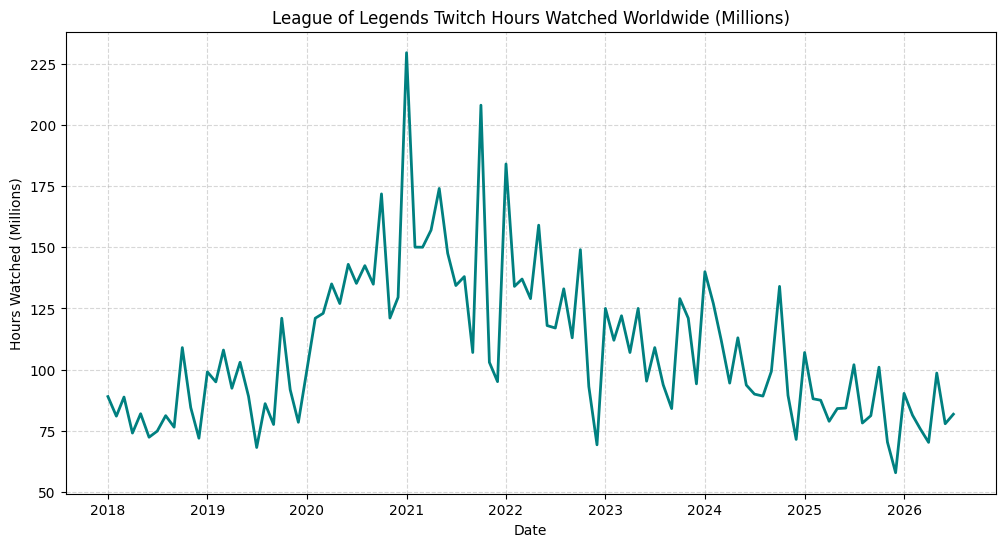

In [102]:
# First, load the data
df = pd.read_csv('/number_of_hours_watched_of_league_of_legends_on_twitch_worldwide_from_january_2018_to_july_2026_in_millions.csv')

# Rename the first column to 'date'
df = df.rename(columns={df.columns[0]: 'date'})

# Convert 'date' to datetime format for proper sorting and plotting
df['date'] = pd.to_datetime(df['date'], format='%Y-%m')

# Display the updated dataframe
display(df.head())

# Plot the line chart
plt.figure(figsize=(12, 6))
plt.plot(df['date'], df['Number of hours watched in millions'], color='teal', linewidth=2)
plt.title('League of Legends Twitch Hours Watched Worldwide (Millions)')
plt.xlabel('Date')
plt.ylabel('Hours Watched (Millions)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


#Plot the other line chart (I prefer this  chart because it is more interactive)
fig = px.line(df, x='date',y='Number of hours watched in millions', color_discrete_sequence=  ['teal'] , title='League of Legends Twitch Hours Watched Worldwide (Millions)')
fig.show()

From observing this line chart, it seems that there is a cyclical pattern of January and October being recorded as the most watched months of each and every year.

*January is when the regional tournaments begin

*October is when the world championship series take place

Therefore, a holiday component should be modeled to capture the surge in January and October

However, i am going to create two different models, one with and the other wthout this 'holiday' effect to highlight its importance


Fitting Prophet model...
Model fitting completed!
Forecast Summary:
Forecast period: 2018-01-01 00:00:00 to 2027-06-30 00:00:00
Number of future periods: 12
Mean predicted hours: 103.95M
Forecast uncertainty (std): 28.47M

Last 10 forecasted values:
            ds       yhat  yhat_lower  yhat_upper
105 2026-09-30  93.992903   66.661459  119.420887
106 2026-10-31  74.603227   48.736506  102.940459
107 2026-11-30  40.119007   11.612410   66.194882
108 2026-12-31  57.800728   29.330825   82.623529
109 2027-01-31  80.863094   56.135970  107.520305
110 2027-02-28  75.299030   48.663023  103.413435
111 2027-03-31  53.769321   24.972440   82.279564
112 2027-04-30  83.070726   52.719288  111.177884
113 2027-05-31  46.892763   17.722997   76.664677
114 2027-06-30  51.732492   21.783862   79.595142


/usr/local/lib/python3.13/dist-packages/prophet/forecaster.py:2206: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



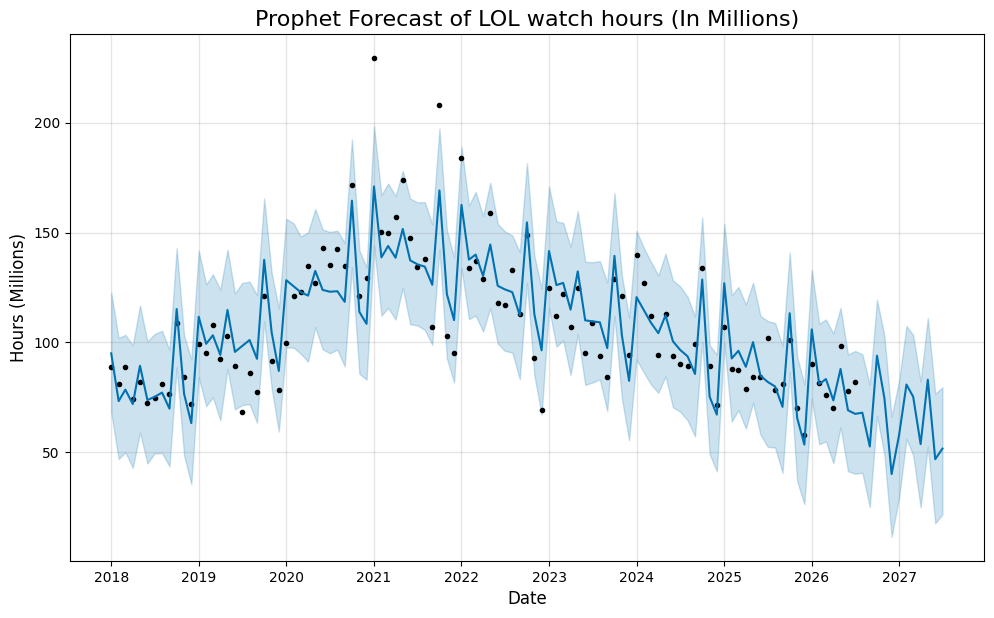

Plotting interactive decomposed components (Trend and Seasonality)...


/usr/local/lib/python3.13/dist-packages/plotly/io/_json.py:560: UserWarning:

Discarding nonzero nanoseconds in conversion.



In [94]:
#First model: Prophet without holiday component


# Prepare the data for Prophet by renaming columns to 'ds' and 'y'
prophet_df = df.rename(columns={'date': 'ds', 'Number of hours watched in millions': 'y'})
# Initialize the Prophet model and pass the holidays dataframe
model = Prophet(
    # seasonality setting
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,

    # trend setting
    changepoint_prior_scale=0.05,
    changepoint_range=0.90,

    # uncertainty interval
    interval_width=0.95,

)

print("Fitting Prophet model...")
model.fit(prophet_df)
print("Model fitting completed!")

# Create a future dataframe for 12 months ahead
future = model.make_future_dataframe(periods=12, freq='M')

# Predict using the model
forecast = model.predict(future)

print("Forecast Summary:")
print(f"Forecast period: {future['ds'].min()} to {future['ds'].max()}")
print(f"Number of future periods: {len(future) - len(df)}")
print(f"Mean predicted hours: {forecast['yhat'].mean():.2f}M")
print(f"Forecast uncertainty (std): {forecast['yhat'].std():.2f}M")

# Show last few predictions
print("\nLast 10 forecasted values:")
print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(10))

fig1 = model.plot(forecast)
plt.title("Prophet Forecast of LOL watch hours (In Millions)", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Hours (Millions)", fontsize=12)
plt.show()

# Import the plotly integration for Prophet
from prophet.plot import plot_components_plotly

# Generate and display the interactive components plot
print("Plotting interactive decomposed components (Trend and Seasonality)...")
fig_components = plot_components_plotly(model, forecast)
fig_components.show()


Fitting Prophet model...
Model fitting completed!


/usr/local/lib/python3.13/dist-packages/prophet/forecaster.py:2206: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



Forecast Summary:
Forecast period: 2018-01-01 00:00:00 to 2027-06-30 00:00:00
Number of future periods: 12
Mean predicted hours: 104.04M
Forecast uncertainty (std): 28.82M

Last 10 forecasted values:
            ds       yhat  yhat_lower  yhat_upper
105 2026-09-30  91.178971   64.369128  116.978662
106 2026-10-31  68.197200   40.365185   95.568492
107 2026-11-30  37.028752   11.200191   63.147293
108 2026-12-31  75.346332   49.376959  101.899278
109 2027-01-31  74.217388   51.159759   98.107817
110 2027-02-28  69.759950   42.999468   96.112439
111 2027-03-31  53.945360   27.140988   79.018032
112 2027-04-30  83.829919   59.093375  109.810865
113 2027-05-31  52.020578   24.727008   77.386139
114 2027-06-30  56.027969   30.206385   83.143650


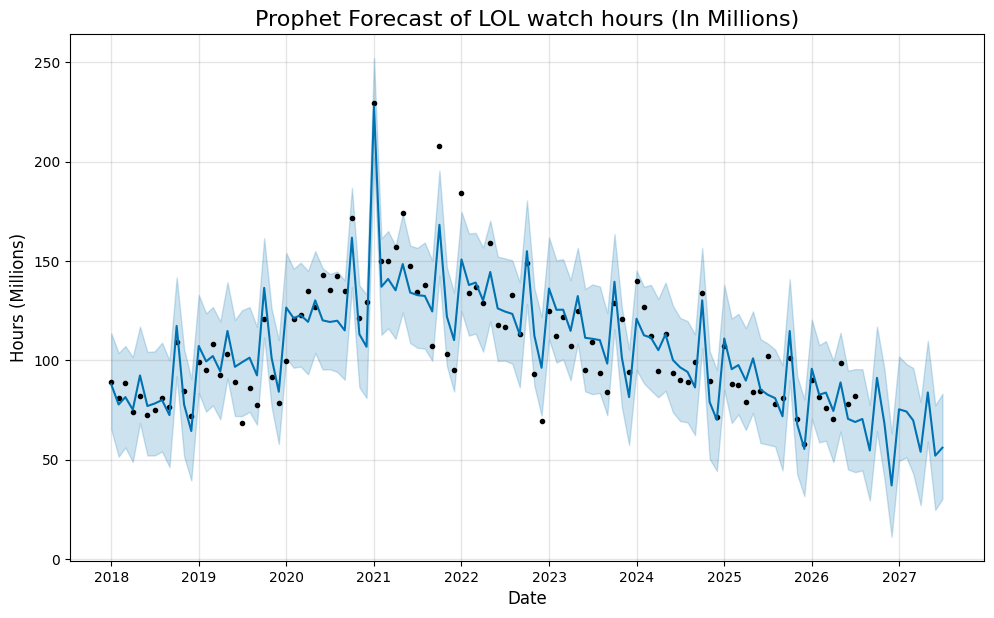

Plotting interactive decomposed components (Trend and Seasonality)...


/usr/local/lib/python3.13/dist-packages/plotly/io/_json.py:560: UserWarning:

Discarding nonzero nanoseconds in conversion.



In [95]:
#Second model: Prophet with holiday component


# Prepare the data for Prophet by renaming columns to 'ds' and 'y'
prophet_df = df.rename(columns={'date': 'ds', 'Number of hours watched in millions': 'y'})

# Create the holiday dataframe with matching array lengths (9 items each)
# Note: Prophet requires the event label column to be named 'holiday'
world_championship_regional= pd.DataFrame(
    {
        "holiday": [
            "world_championship_series",
            "world_championship_series",
            "world_championship_series",
            "world_championship_series",
            "world_championship_series",
            "world_championship_series",
            "world_championship_series",
            "world_championship_series",
            "world_championship_series",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
            "Regional_tournament_begin",
        ],
        "ds": pd.to_datetime([
            "2018-10-01",
            "2019-10-01",
            "2020-10-01",
            "2021-10-01",
            "2022-10-01",
            "2023-10-01",
            "2024-10-01",
            "2025-10-01",
            "2026-10-01",
            "2021-01-01",
            "2021-01-01",
            "2021-01-01",
            "2021-01-01",
            "2021-01-01",
            "2021-01-01",
            "2021-01-01",
            "2021-01-01",
            "2021-01-01",
        ]),
        "lower_window": [-15, -15, -15, -15, -15, -15, -15, -15, -15,-1,-1,-1,-1,-1,-1,-1,-1,-1], # adjusted window for month-scale data
        "upper_window": [15, 15, 15, 15, 15, 15, 15, 15, 15,1,1,1,1,1,1,1,1,1],       # adjusted window for month-scale data
    }
)

# Initialize the Prophet model and pass the holidays dataframe
model = Prophet(
    # seasonality setting
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,

    # trend setting
    changepoint_prior_scale=0.05,
    changepoint_range=0.90,

    # uncertainty interval
    interval_width=0.95,

    # Include the holiday/special events
    holidays=world_championship_regional
)

print("Fitting Prophet model...")
model.fit(prophet_df)
print("Model fitting completed!")

# Create a future dataframe for 12 months ahead
future = model.make_future_dataframe(periods=12, freq='M')

# Predict using the model
forecast = model.predict(future)

print("Forecast Summary:")
print(f"Forecast period: {future['ds'].min()} to {future['ds'].max()}")
print(f"Number of future periods: {len(future) - len(df)}")
print(f"Mean predicted hours: {forecast['yhat'].mean():.2f}M")
print(f"Forecast uncertainty (std): {forecast['yhat'].std():.2f}M")

# Show last few predictions
print("\nLast 10 forecasted values:")
print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(10))

fig1 = model.plot(forecast)
plt.title("Prophet Forecast of LOL watch hours (In Millions)", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Hours (Millions)", fontsize=12)
plt.show()

# Import the plotly integration for Prophet
from prophet.plot import plot_components_plotly

# Generate and display the interactive components plot
print("Plotting interactive decomposed components (Trend and Seasonality)...")
fig_components = plot_components_plotly(model, forecast)
fig_components.show()

**Next, i would like to compare the two Prophet models**

To do so, i would once again write the codes for the two models (Could skip but it helps make the codes more readible)

I will call the one without holiday component "baseline_model" and the one with holiday component "refinded_model"

In [96]:
# 1. Baseline Model (No Holidays) - fit and predict
baseline_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.05,
    changepoint_range=0.90,
    interval_width=0.95
)
baseline_model.fit(prophet_df)
forecast_baseline = baseline_model.predict(future)

# 2. Refined Model (With Holidays/Special Events) - fit and predict
refined_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.05,
    changepoint_range=0.90,
    interval_width=0.95,
    holidays=world_championship_regional
)
refined_model.fit(prophet_df)
forecast_refined = refined_model.predict(future)

# Create a consolidated DataFrame for comparison
comparison_df = pd.DataFrame({
    'date': future['ds'],
    'Baseline Prediction (No Events)': forecast_baseline['yhat'],
    'Refined Prediction (With Events)': forecast_refined['yhat']
})

# Merge with the actual historical data
comparison_df = pd.merge(comparison_df, prophet_df, left_on='date', right_on='ds', how='left').drop(columns=['ds'])
comparison_df = comparison_df.rename(columns={'y': 'Actual Watch Hours'})

# Plot using interactive Plotly
import plotly.graph_objects as go

fig_compare = go.Figure()

# Add actual hours
fig_compare.add_trace(go.Scatter(
    x=comparison_df['date'],
    y=comparison_df['Actual Watch Hours'],
    mode='lines+markers',
    name='Actual',
    line=dict(color='black', width=2)
))

# Add baseline prediction
fig_compare.add_trace(go.Scatter(
    x=comparison_df['date'],
    y=comparison_df['Baseline Prediction (No Events)'],
    mode='lines',
    name='Baseline (No Events)',
    line=dict(color='crimson', dash='dash')
))

# Add refined prediction
fig_compare.add_trace(go.Scatter(
    x=comparison_df['date'],
    y=comparison_df['Refined Prediction (With Events)'],
    mode='lines',
    name='Refined (With Events)',
    line=dict(color='teal', width=2)
))

# Layout details
fig_compare.update_layout(
    title='Model Comparison: Baseline vs. Event-Refined Forecasts',
    xaxis_title='Date',
    yaxis_title='Hours Watched (Millions)',
    legend_title='Series',
    template='plotly_white',
    hovermode='x unified'
)

fig_compare.show()

**Data interpretation**

It appears that the refined model performed more accurately when it comes to fitting to the actual data, particularly the peak in January 2021 being captured by the refined model.

A more numerical evaluation would be needed (RMSE, MAE,...)

In [97]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import numpy as np

# Filter the comparison dataframe to only include historical dates where actual values exist
historical_eval = comparison_df.dropna(subset=['Actual Watch Hours']).copy()

y_true = historical_eval['Actual Watch Hours']
y_pred_baseline = historical_eval['Baseline Prediction (No Events)']
y_pred_refined = historical_eval['Refined Prediction (With Events)']

# Calculate metrics for Baseline Model
mse_baseline = mean_squared_error(y_true, y_pred_baseline)
rmse_baseline = np.sqrt(mse_baseline)
mae_baseline = mean_absolute_error(y_true, y_pred_baseline)
mape_baseline = mean_absolute_percentage_error(y_true, y_pred_baseline) * 100

# Calculate metrics for Refined Model
mse_refined = mean_squared_error(y_true, y_pred_refined)
rmse_refined = np.sqrt(mse_refined)
mae_refined = mean_absolute_error(y_true, y_pred_refined)
mape_refined = mean_absolute_percentage_error(y_true, y_pred_refined) * 100

# Create a comparison DataFrame
metrics_df = pd.DataFrame({
    'Metric': ['MSE', 'RMSE', 'MAE', 'MAPE (%)'],
    'Baseline Model': [mse_baseline, rmse_baseline, mae_baseline, mape_baseline],
    'Refined Model (With Events)': [mse_refined, rmse_refined, mae_refined, mape_refined]
})

display(metrics_df.round(3))

,Metric,Baseline Model,Refined Model (With Events)
0,MSE,192.505,166.628
1,RMSE,13.875,12.908
2,MAE,10.861,10.183
3,MAPE (%),10.129,9.567


By observing the MAPE score for the two models, we can observe that the refined model performed better with 9.567% error while the baseline model yielded a 10.1% error

Across all evaluation metrics, the refined model performed better

** FInal takeaway**

The prophet model works best when there is domain knowledge. Had i not known that the surges in January and October were special events, i would not have modeled the prophet framwork properly, and thus, would produce a less accurate and reliable forecast.
